# M2.2 — Filtragem na frequência

**Responsável: Heloisa Cavalcante Born** · Grupo: Gustavo Corrêa de Mello e João Paulo Jorge Aimi.

Imagem `2009_003974.jpg` do VOC2012 (`car_04` na galeria), RGB 500 × 335, conjunto Main/train. A cópia original não contém caixas. Fonte, SHA-256 e justificativa em `data/README.md`.

Este notebook executa apenas a frente de filtragem. Watershed/SLIC e células pertencem às outras frentes.


In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro da pasta do projeto.")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.experimento_frequencia import executar
from IPython.display import display, Image, Markdown
import numpy as np


## 1. Modelo de ruído e plano experimental

Usamos $I_r=\operatorname{clip}(I+\eta,0,1)$, com $\eta\sim N(0,0{,}08^2)$, independente por canal; seed 42. A imagem limpa fica reservada como referência. O clipping torna o ruído efetivo não exatamente gaussiano perto dos extremos.

Comparamos máscaras Gaussianas e Butterworth de ordem 2 em uma grade fixa de 11 valores de corte, sem mudar o ruído entre execuções. As imagens não são redimensionadas. O padding refletido de 32 pixels reduz a descontinuidade artificial nas bordas da extensão periódica da FFT.


## 2. Filtros, transformada inversa e métricas

Para cada canal, calculamos $F=\operatorname{fftshift}(\operatorname{FFT2}(I_r))$, $G=HF$ e $I_f=\Re\{\operatorname{IFFT2}(\operatorname{ifftshift}(G))\}$. Depois, recortamos o padding e limitamos em [0,1], sem normalização por mínimo/máximo.

Com $D$ em ciclos/pixel, $H_G=\exp[-D^2/(2D_0^2)]$ e $H_B=[1+(D/D_0)^{2n}]^{-1}$. O mesmo $D_0$ não representa ganho idêntico entre as famílias: $H_G(D_0)\approx0{,}607$ e $H_B(D_0)=0{,}5$.

$MSE=\frac1N\sum (I-I_f)^2$ e $PSNR=10\log_{10}(1/MSE)$ para intervalo [0,1]. Média sobre todos os pixels e canais. PSNR é qualidade de restauração, não qualidade semântica de segmentação. SSIM é opcional no enunciado e não foi incluído nesta frente.

As máscaras, o ruído e as métricas são próprios; NumPy fornece somente operações numéricas e FFT. Não usamos filtros prontos.


In [2]:
# Para outra imagem, trocar CAMINHO_IMAGEM e escolher outra pasta de saída.
CAMINHO_IMAGEM = ROOT / "data/originais/2009_003974.jpg"
SAIDA = ROOT / "resultados/frequencia"
manifesto, tabela = executar(CAMINHO_IMAGEM, SAIDA, sigma=0.08, seed=42)
print("Imagem:", manifesto["imagem"], "Formato:", manifesto["shape"])
print("PSNR ruidosa:", round(manifesto["psnr_ruidosa_db"], 4), "dB")
print("Melhor configuração na grade:", manifesto["escolha"])


Imagem: 2009_003974.jpg Formato: [335, 500, 3]
PSNR ruidosa: 22.6133 dB
Melhor configuração na grade: {'filtro': 'gaussiano', 'corte': 0.25, 'ordem': '', 'mse': 0.0024442264447737537, 'psnr_db': 26.118585614572897, 'ganho_db': 3.505264161989871}


## 3. Comparação quantitativa — todas as configurações

| Filtro | Corte (ciclos/pixel) | PSNR (dB) | Ganho (dB) |
|---|---:|---:|---:|
| gaussiano | 0.02 | 18.0294 | -4.5839 |
| gaussiano | 0.04 | 20.2190 | -2.3943 |
| gaussiano | 0.06 | 21.6268 | -0.9865 |
| gaussiano | 0.08 | 22.5989 | -0.0144 |
| gaussiano | 0.10 | 23.3532 | +0.7399 |
| gaussiano | 0.12 | 23.9771 | +1.3637 |
| gaussiano | 0.16 | 24.9675 | +2.3542 |
| gaussiano | 0.20 | 25.6717 | +3.0584 |
| gaussiano | 0.25 | 26.1186 | +3.5053 |
| gaussiano | 0.35 | 25.8569 | +3.2436 |
| gaussiano | 0.50 | 24.7833 | +2.1700 |
| butterworth | 0.02 | 17.6998 | -4.9135 |
| butterworth | 0.04 | 19.6736 | -2.9398 |
| butterworth | 0.06 | 21.1701 | -1.4432 |
| butterworth | 0.08 | 22.1911 | -0.4222 |
| butterworth | 0.10 | 22.9308 | +0.3174 |
| butterworth | 0.12 | 23.5256 | +0.9123 |
| butterworth | 0.16 | 24.4737 | +1.8604 |
| butterworth | 0.20 | 25.1831 | +2.5698 |
| butterworth | 0.25 | 25.7652 | +3.1519 |
| butterworth | 0.35 | 25.9753 | +3.3619 |
| butterworth | 0.50 | 24.8951 | +2.2818 |

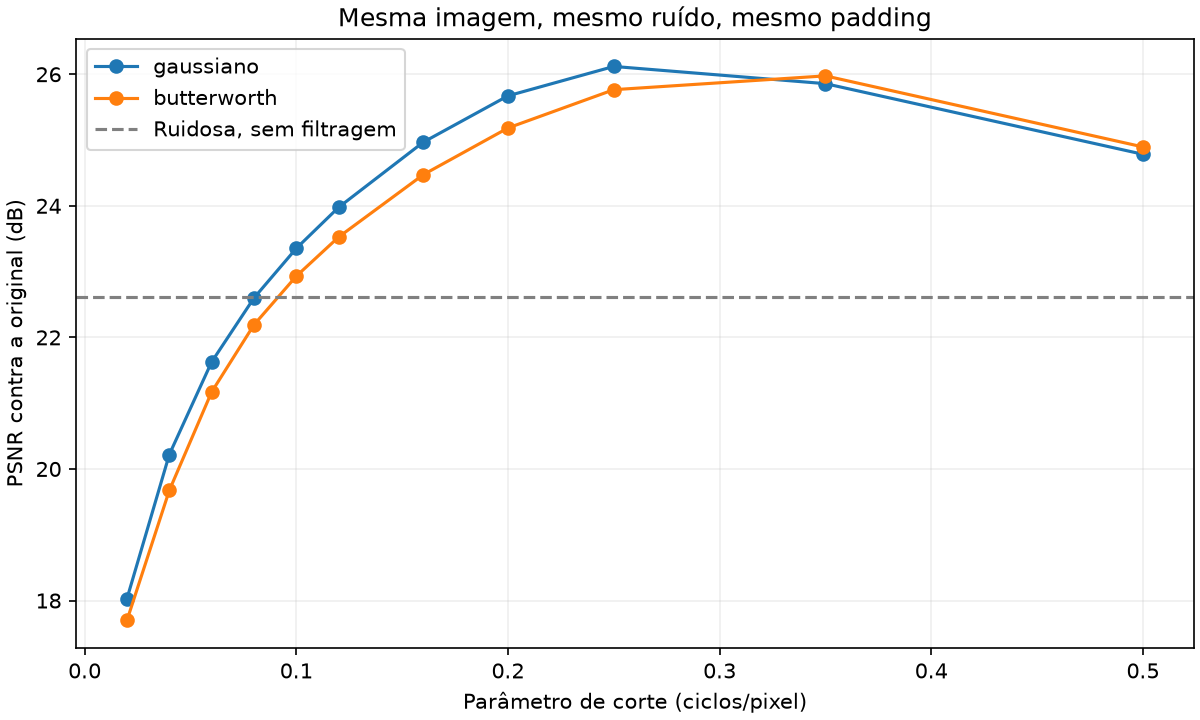

In [3]:
cabecalho = "| Filtro | Corte (ciclos/pixel) | PSNR (dB) | Ganho (dB) |\n|---|---:|---:|---:|\n"
linhas = [f"| {r['filtro']} | {r['corte']:.2f} | {r['psnr_db']:.4f} | {r['ganho_db']:+.4f} |" for r in tabela]
display(Markdown(cabecalho + "\n".join(linhas)))
display(Image(filename=str(SAIDA / "psnr_por_corte.png")))


## 4. Imagens e recorte idêntico para examinar os contornos

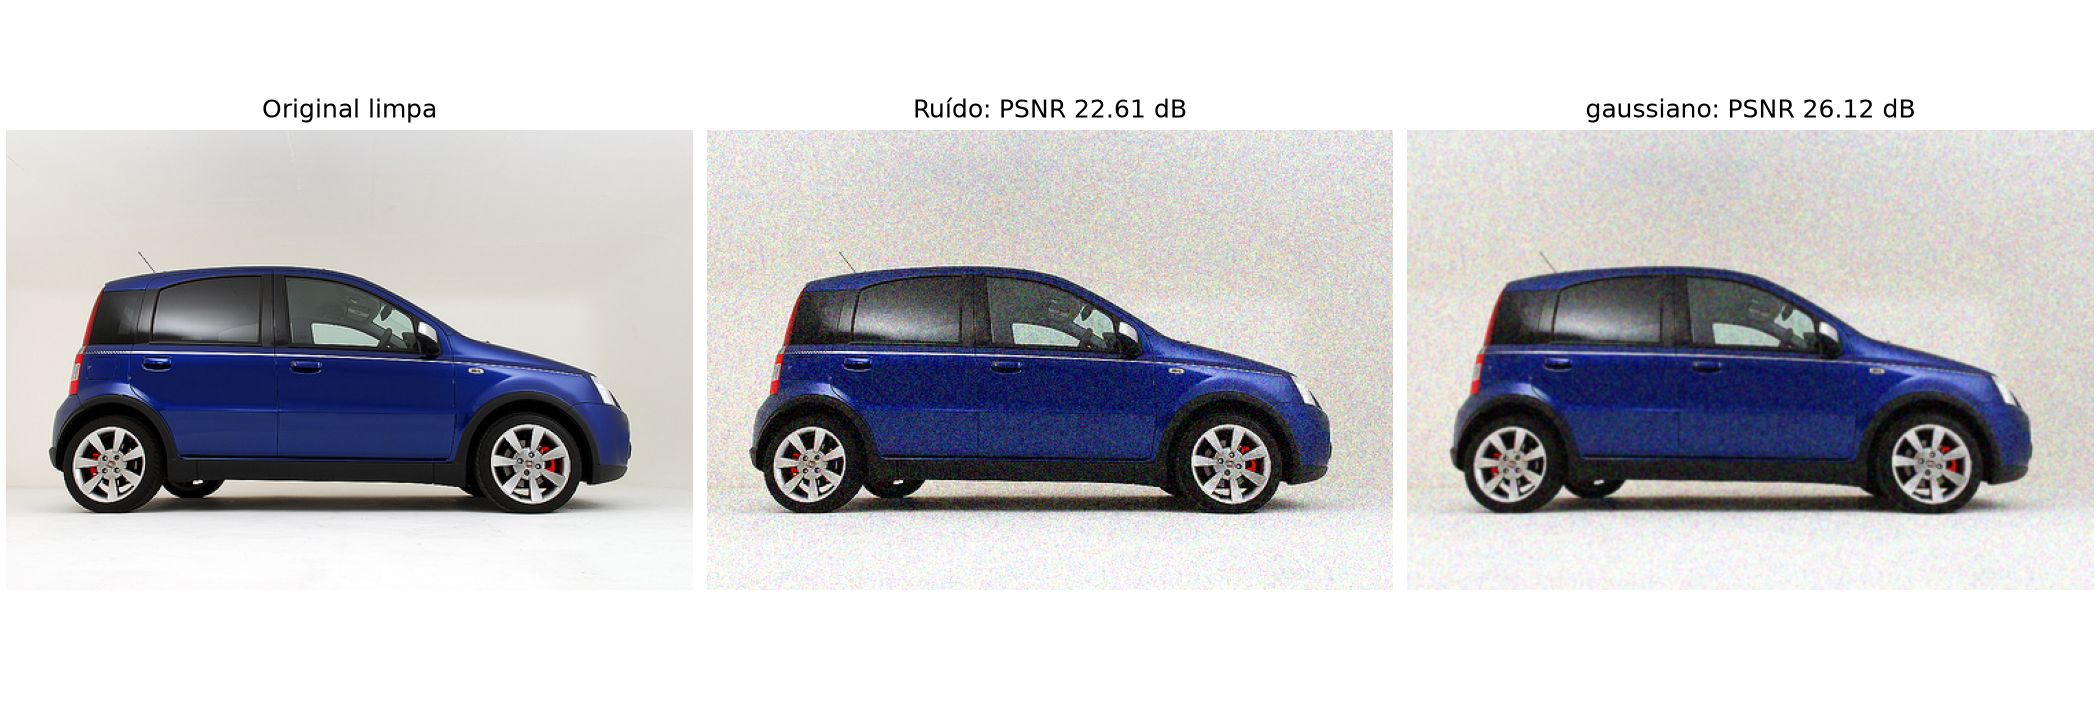

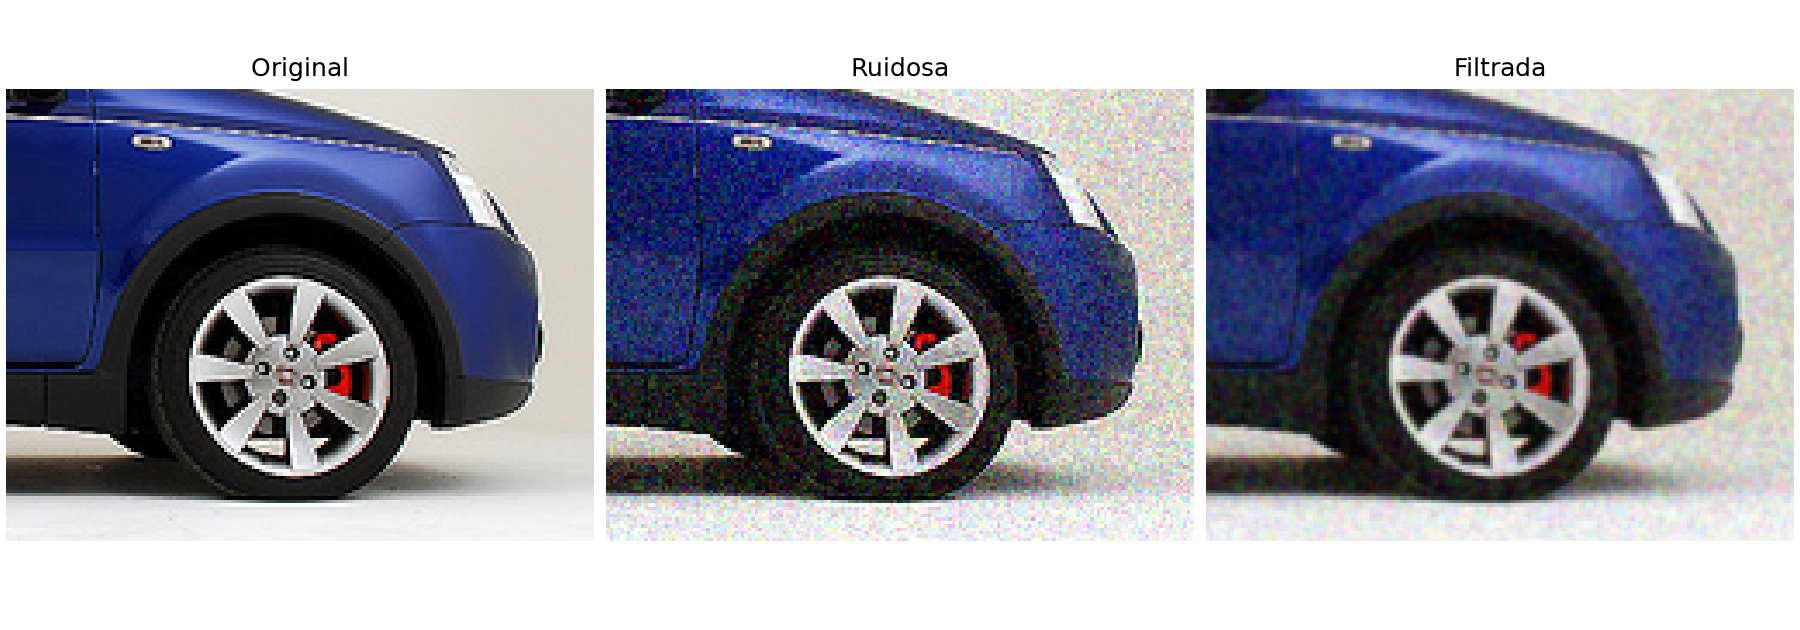

In [4]:
display(Image(filename=str(SAIDA / "comparacao_imagens.png")))
display(Image(filename=str(SAIDA / "recorte_contornos.png")))

## 5. Espectros antes/depois e máscara

Mostramos log(1 + amplitude média dos canais), com a mesma escala antes e depois. O centro é a frequência zero. Frequências radiais maiores ficam atenuadas pelo passa-baixa. Estes espectros correspondem à imagem com padding; o produto complexo é levado à inversa e recortado para 500 × 335.


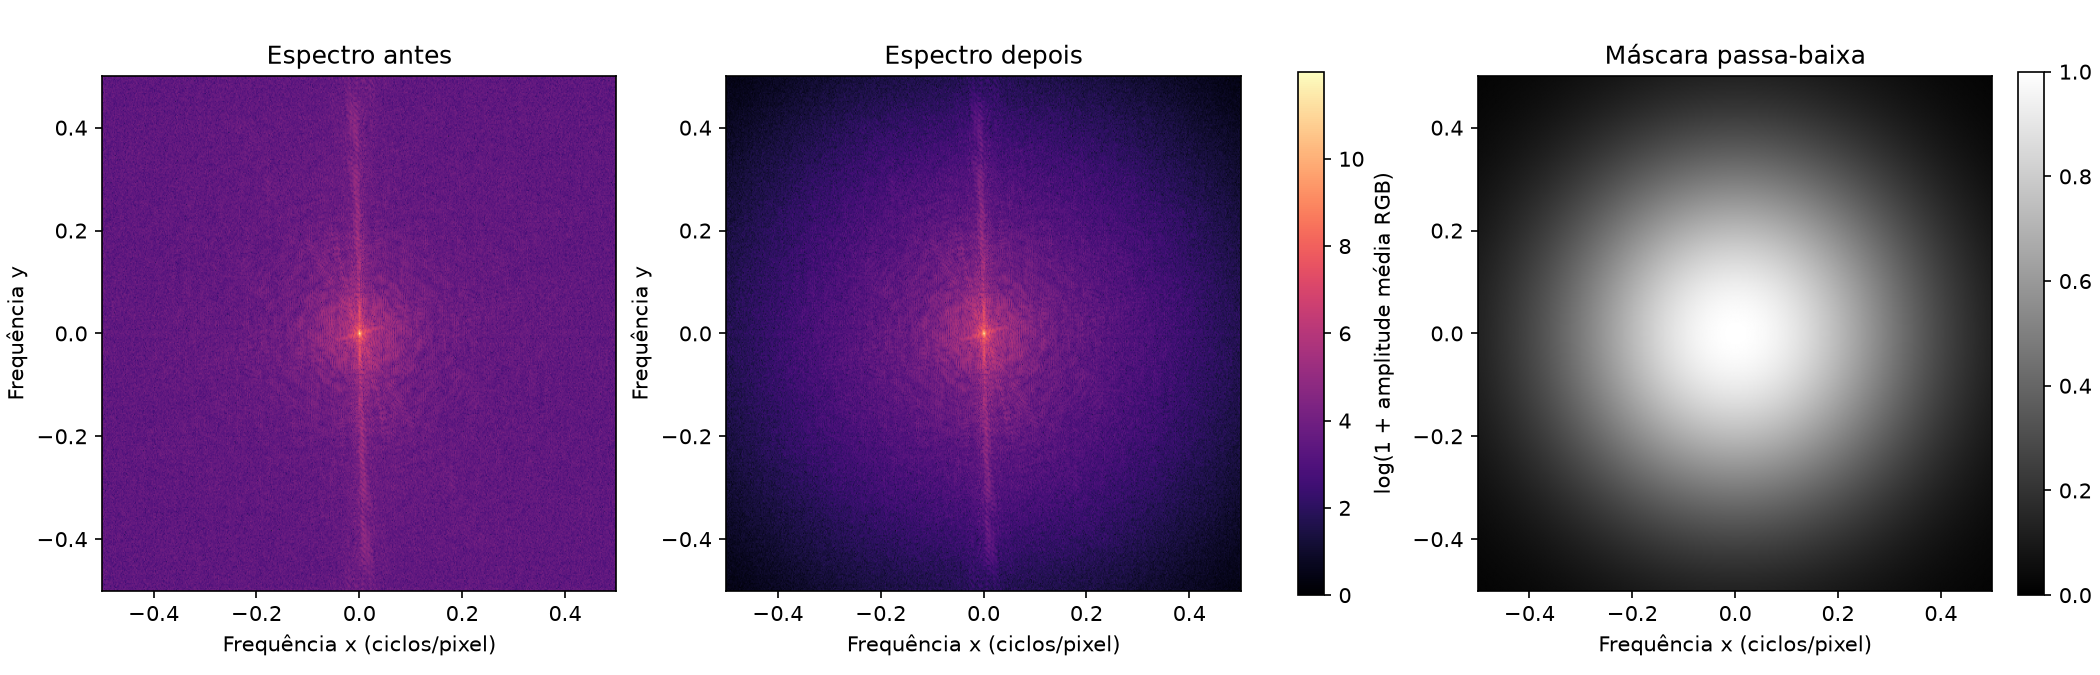

Maior resíduo imaginário da IFFT: 4.805630676128216e-16


In [5]:
display(Image(filename=str(SAIDA / "espectros_mascara.png")))
print("Maior resíduo imaginário da IFFT:", manifesto["residuo_imaginario_max"])

## 6. Discussão e limites

O maior PSNR da grade é uma escolha feita **com acesso à imagem limpa nesta imagem e seed**, apropriada para o experimento controlado. Não demonstra generalização e não é uma seleção cega de parâmetros. Cortes baixos tendem a apagar contornos; altos deixam mais ruído. Rodas, janelas e reflexos são regiões importantes para a inspeção visual. As duas famílias têm respostas diferentes mesmo com o mesmo corte.

A redução do erro de restauração deve ser comparada posteriormente com os mapas e contornos de Gustavo: não garante melhor Watershed/SLIC. A imagem não tem máscara de segmentação declarada; não usamos uma caixa de detecção como máscara de referência.


In [6]:
e = manifesto["escolha"]
display(Markdown(f"Nesta execução, **{e['filtro']}**, corte **{e['corte']:.2f} ciclos/pixel**, atingiu **{e['psnr_db']:.4f} dB**, ganho de **{e['ganho_db']:.4f} dB** sobre a ruidosa."))
dados = np.load(SAIDA / "entradas_segmentacao.npz")
for nome in dados.files:
    print(nome, dados[nome].shape, dados[nome].dtype, dados[nome].min(), dados[nome].max())
assert all(dados[n].shape == dados["original_rgb"].shape for n in dados.files)


Nesta execução, **gaussiano**, corte **0.25 ciclos/pixel**, atingiu **26.1186 dB**, ganho de **3.5053 dB** sobre a ruidosa.

original_rgb (335, 500, 3) float64 

0.0 1.0
ruidosa_rgb (335, 500, 3) float64 0.0 1.0


filtrada_rgb (335, 500, 3) float64 0.0 1.0


## 7. Entrega para Gustavo e reprodução

`resultados/frequencia/entradas_segmentacao.npz` contém `original_rgb`, `ruidosa_rgb` e `filtrada_rgb` em float64 [0,1], mesmas dimensões. Usar esses arrays, não as cópias PNG arredondadas. Parâmetros, versões e métricas estão em `parametros.json`; a tabela completa está em `comparacao_filtros.csv`.

Se o segmentador precisar de cinza, aplicar a mesma conversão manual às três condições, sem trocar as imagens ou gerar novo ruído. Não reutilizar os espectros como entrada espacial.

Para reproduzir: instalar `requirements.txt`, obter a imagem com `python scripts/baixar_imagem_voc2012.py` e executar este notebook do início ao fim. Testes matemáticos: `python -m unittest discover -s tests -v`.

Referências: enunciado e material de filtragem no domínio da frequência da disciplina; [documentação NumPy FFT](https://numpy.org/doc/stable/reference/routines.fft.html); [VOC2012 oficial](https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/voc2012/). O código desta frente foi escrito para este projeto.
